# 04 Siamese architectures

**Notebook 4 of 6, xBD building damage assessment**

The five class U-Net from notebook 3 stacks pre and post into six input
channels, so the two time points are compared in the very first convolution.
Two architectures that move that comparison to the other end of the network:

| model | encoder | merge |
|---|---|---|
| Siamese U-Net | own U-Net, encoder initialized from UNet1 | on every scale |
| Siamese ResNet50 | ImageNet pretrained ResNet50 | once at the end |

Both run the same encoder twice, once on pre and once on post. The Siamese U-Net
stays as close as possible to the stacked baseline; the ResNet50 is the final
model with a pretrained encoder and a stronger training setup.

Requires `01_data_check.ipynb` and the validation tiles from
`03_scale_to_all_events.ipynb`.

## 0. Setup

In [1]:
import os
import sys
from pathlib import Path

root = Path.cwd()
while not (root / "config.py").exists() and root != root.parent:
    root = root.parent
sys.path.insert(0, str(root))

import numpy as np
from PIL import Image
import matplotlib.pyplot as pl
import torch
from torch.utils.data import DataLoader

import config
from common import data, crops, models, losses, train, evaluate, plots

pl.rcParams["figure.dpi"] = 120
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

paths = {split: found for split, found in data.resolve_splits(config.DATA_ROOT).items()
         if split in ("train", "test", "tier3")}
file_lists = {split: data.list_pre_images(paths[split]["images"]) for split in paths}
for split, files in file_lists.items():
    print(f"{split}: {len(files)} pre-disaster images")


/DATA/schrepel/ml_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


device: cuda
train: 2746 pre-disaster images
test: 917 pre-disaster images
tier3: 6288 pre-disaster images


## 1. Data and validation set

Same basis as notebook 3: all events, building filter, 12 crops per filtered
test image.

In [2]:
all_building_files = []
for split in paths:
    for pre_image in file_lists[split]:
        stem = pre_image.replace("_pre_disaster.png", "")
        target = np.array(Image.open(
            os.path.join(paths[split]["targets"], f"{stem}_pre_disaster_target.png")))
        if (target > 0).mean() >= config.MIN_BUILDING_FRACTION:
            all_building_files.append((split, stem))

train_files = [(s, stem) for s, stem in all_building_files if s in ("train", "tier3")]
val_files = [(s, stem) for s, stem in all_building_files if s == "test"]

print(f"{len(train_files)} training images, {len(val_files)} validation images")

4836 training images, 676 validation images


In [3]:
val_tiles_all = train.load_val_tiles("val_damage_raw_tiles_all_events.pt")
crops.describe_tiles(val_tiles_all, "all events")

loaded /DATA/schrepel/xbd_new/val_tiles/val_damage_raw_tiles_all_events.pt (8112 tiles)


all events: 8112 tiles, 81.8% positive, 3.07% damaged building pixels


## 2. Architectures, datasets and training loop

The Siamese models take pre and post as separate inputs and need their own
dataset classes. The stacked ones stay for the baseline U-Net in the comparison
at the end.

The ResNet encoder was pretrained on ImageNet and expects inputs normalized
with the ImageNet mean and standard deviation, so its datasets and its
predictor run with `normalize=True`. The Siamese U-Net keeps plain [0, 1]
inputs, otherwise the weights transferred from UNet1 would no longer match.

In [4]:
val_loader_siamese = DataLoader(
    crops.FixedSiameseDataset(val_tiles_all, crops.damage_identity),
    batch_size=config.BATCH_SIZE, shuffle=False)
val_loader_resnet = DataLoader(
    crops.FixedSiameseDataset(val_tiles_all, crops.damage_identity, normalize=True),
    batch_size=config.BATCH_SIZE, shuffle=False)
val_loader_stacked = DataLoader(
    crops.FixedDamageDataset(val_tiles_all, crops.damage_identity),
    batch_size=config.BATCH_SIZE, shuffle=False)

## 3. Siamese U-Net

The encoder comes from the localization U-Net and stays frozen for the first
three epochs, so the randomly initialized decoder cannot destroy it. After that
everything trains at the same constant learning rate. Sampling and augmentation
match the stacked U-Net: building based crops and plain flips.

In [5]:
if not (config.CKPT_DIR / "damage_siamese_best.pt").exists():
    train_loader_siamese = DataLoader(
        crops.SiameseDamageDataset(train_files, paths, crops.damage_identity, n_crops=12, augment=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)

    torch.manual_seed(357)
    model_siamese = models.SiameseUNet(in_channels=3, out_channels=5, base_filters=64, dropout_p=0.2).to(device)
    model_siamese = models.load_encoder_weights(model_siamese, config.CKPT_DIR / "unet_localization_best.pt")

    train.train_model(model_siamese, train_loader_siamese, [val_loader_siamese],
                config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "damage_siamese_best.pt", config.HISTORY_DIR / "history_siamese.pt",
                loss_fn=losses.WeightedMultiClassDiceLoss(n_classes=5, device=device),
                siamese=True,
                freeze_prefixes=("enc1", "enc2", "enc3", "enc4", "bottleneck"),
                warmup_epochs=3)

In [6]:
model_siamese = models.SiameseUNet(in_channels=3, out_channels=5, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_siamese, "damage_siamese_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/damage_siamese_best.pt


SiameseUNet(
  (enc1): DoubleConv(
    (block): Sequential(
      (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc2): DoubleConv(
    (block): Sequential(
      (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (5): ReLU(inplace=True)
    )
  )
  (enc3): DoubleConv(
    (bl

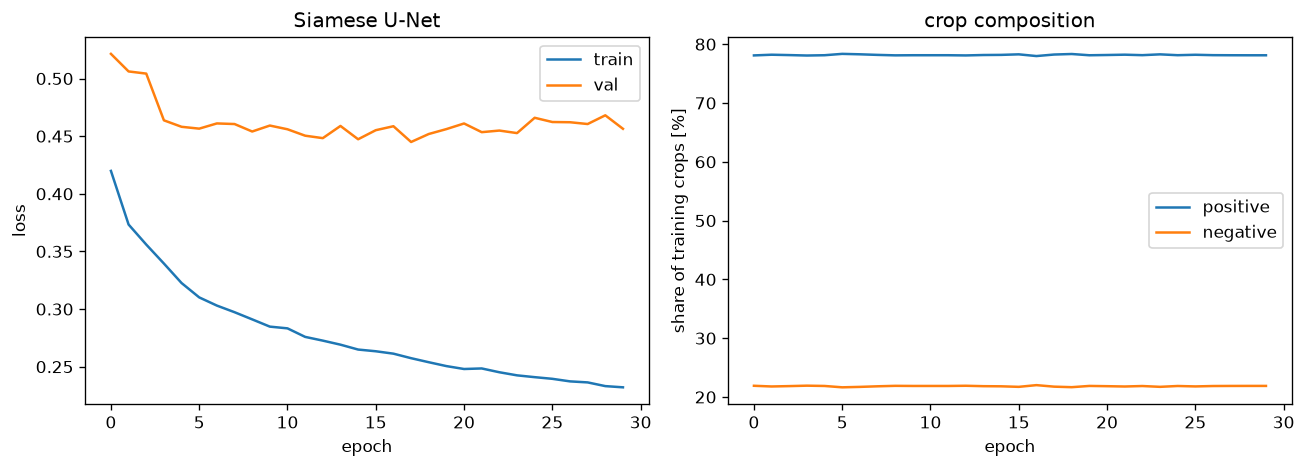

In [7]:
plots.plot_history(train.load_history("history_siamese.pt"), "Siamese U-Net")

In [8]:
results_siamese = evaluate.per_class_metrics(model_siamese, val_loader_siamese, 5, device, siamese=True)
evaluate.print_metrics(results_siamese, config.FIVE_CLASS_NAMES, "Siamese U-Net")

Siamese U-Net
       class   precision    recall      F1
  background       0.979     0.986   0.983
   no-damage       0.841     0.788   0.813
       minor       0.448     0.424   0.436
       major       0.601     0.631   0.616
   destroyed       0.759     0.690   0.723


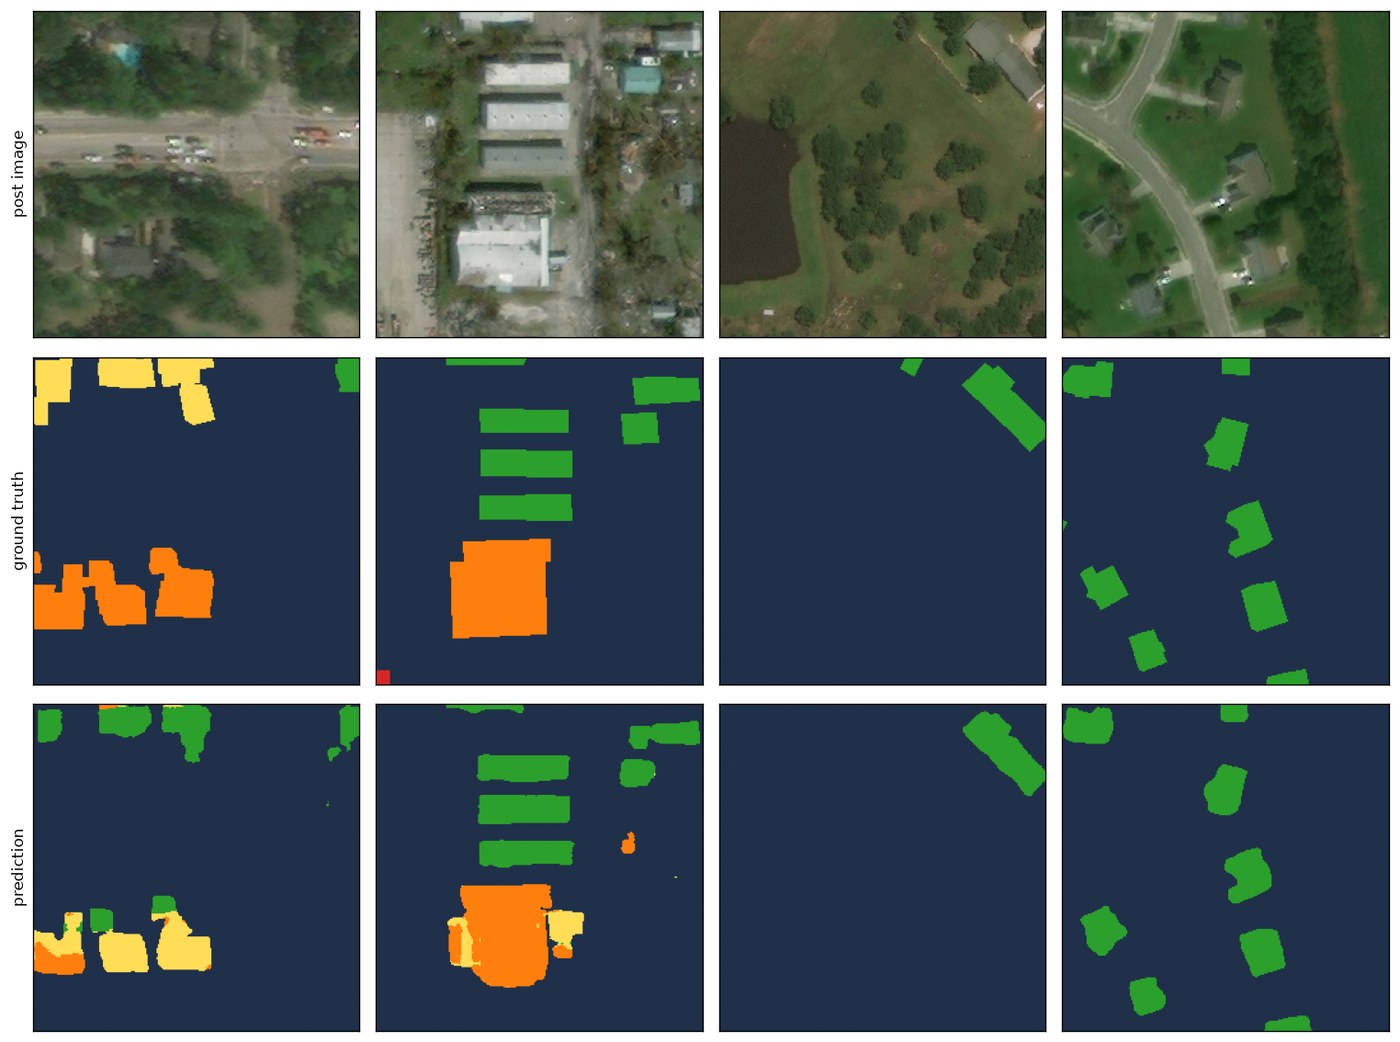

In [9]:
plots.show_examples(plots.make_predictor(model_siamese, device, siamese=True), val_tiles_all,
              crops.damage_identity, plots.FIVE_CLASS_CMAP, n_classes=5)

## 4. Siamese ResNet50

The final model. Compared to the Siamese U-Net it changes encoder, merge point
and training setup:

- ImageNet pretrained ResNet50 with ImageNet normalization, decoder built from
  `encoder.out_channels` and a skip connection on the input image
- pre and post merged once at the end
- half of the training crops must contain damage; rotations, colour jitter and
  scale augmentation on top of the flips
- the pretrained encoder trains at a fifth of the learning rate, decoder and
  head at the full rate, all with cosine decay

In [10]:
if not (config.CKPT_DIR / "damage_siamese_resnet_best.pt").exists():
    train_loader_resnet = DataLoader(
        crops.SiameseDamageDataset(train_files, paths, crops.damage_identity, n_crops=12, augment=True,
                             damage_probability=0.5, normalize=True,
                             scale_range=(0.8, 1.25), rotate=True, color_jitter=True),
        batch_size=config.BATCH_SIZE, shuffle=True, num_workers=4, pin_memory=True)

    torch.manual_seed(357)
    model_resnet = models.SiameseResNetUNet(out_channels=5, encoder_name="resnet50",
                                     encoder_weights="imagenet").to(device)

    train.train_model(model_resnet, train_loader_resnet, [val_loader_resnet],
                config.EPOCHS, config.LEARNING_RATE, device,
                config.CKPT_DIR / "damage_siamese_resnet_best.pt",
                config.HISTORY_DIR / "history_siamese_resnet.pt",
                loss_fn=losses.WeightedMultiClassDiceLoss(n_classes=5, device=device),
                siamese=True,
                slow_prefixes=("encoder",), slow_lr_factor=0.2,
                cosine=True)

In [11]:
# encoder_weights=None: the ImageNet weights are overwritten by the checkpoint anyway
model_resnet = models.SiameseResNetUNet(out_channels=5, encoder_name="resnet50",
                                 encoder_weights=None).to(device)
train.load_checkpoint(model_resnet, "damage_siamese_resnet_best.pt", device)

loaded /DATA/schrepel/xbd_new/checkpoints/damage_siamese_resnet_best.pt


SiameseResNetUNet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): Bottleneck(
        (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (downsample): Seque

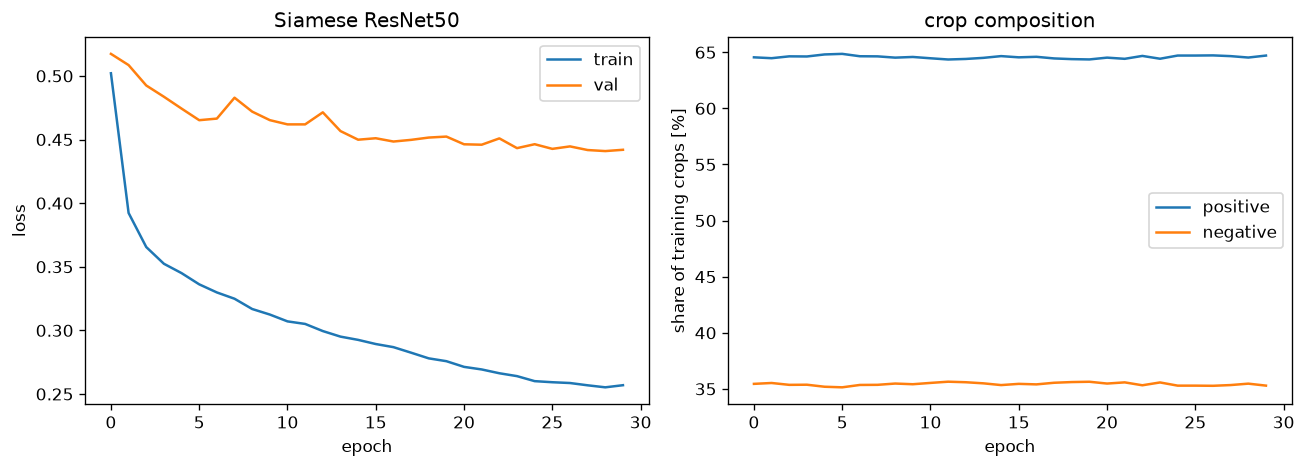

In [12]:
plots.plot_history(train.load_history("history_siamese_resnet.pt"), "Siamese ResNet50")

In [13]:
results_resnet = evaluate.per_class_metrics(model_resnet, val_loader_resnet, 5, device, siamese=True)
evaluate.print_metrics(results_resnet, config.FIVE_CLASS_NAMES, "Siamese ResNet50")

Siamese ResNet50
       class   precision    recall      F1
  background       0.979     0.986   0.982
   no-damage       0.844     0.780   0.811
       minor       0.432     0.486   0.457
       major       0.664     0.662   0.663
   destroyed       0.803     0.667   0.729


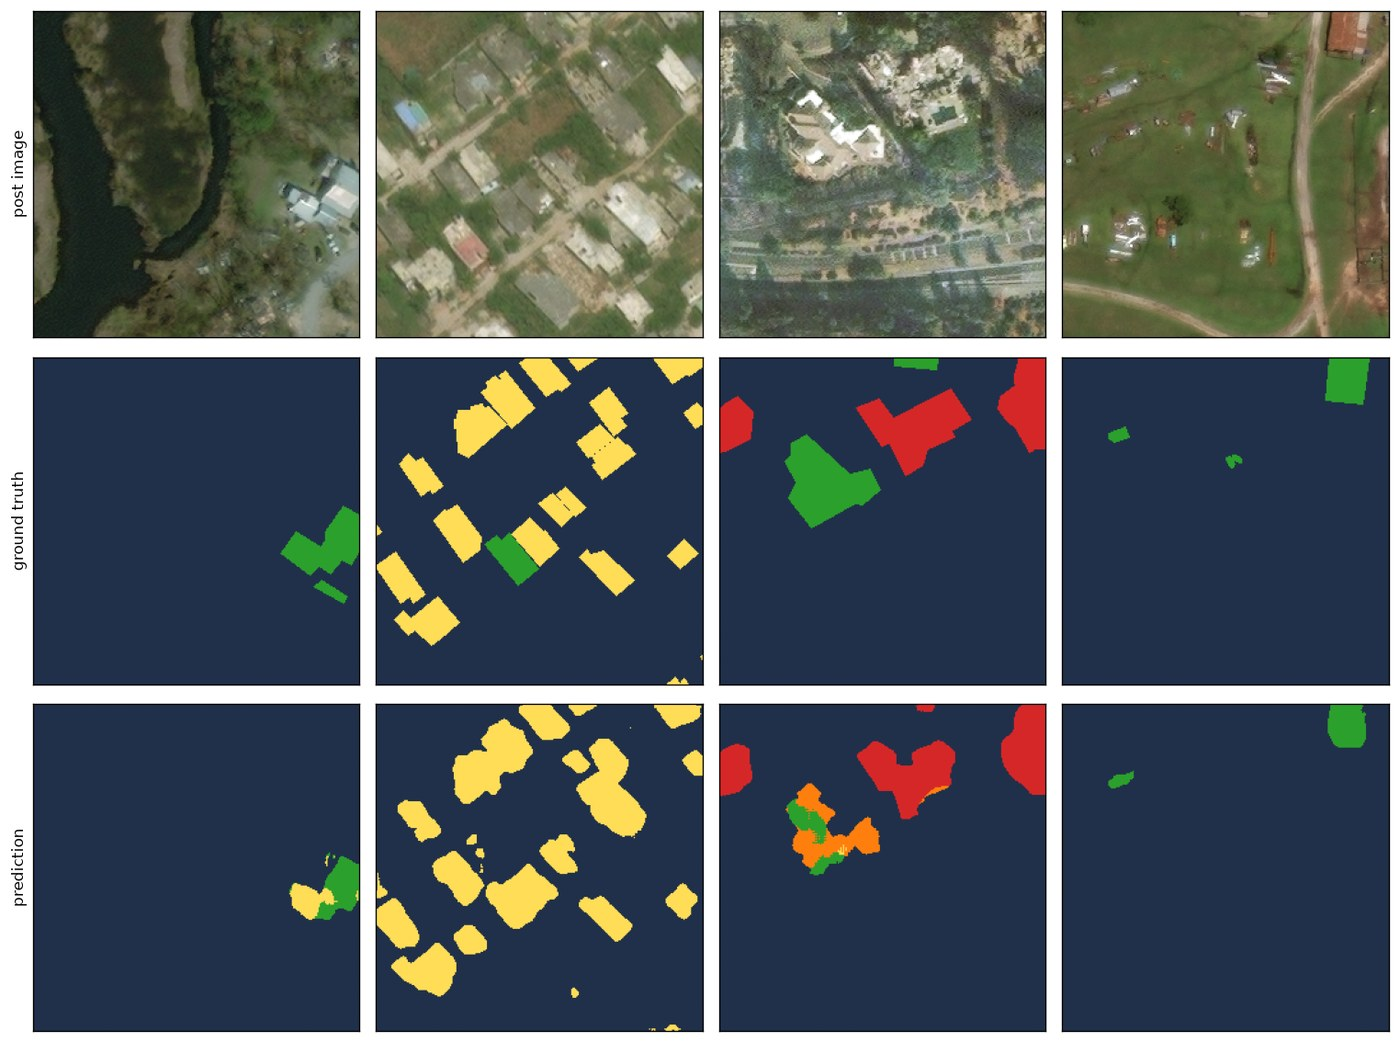

In [14]:
plots.show_examples(plots.make_predictor(model_resnet, device, siamese=True, normalize=True),
              val_tiles_all, crops.damage_identity, plots.FIVE_CLASS_CMAP, n_classes=5)

## 5. Comparison

The stacked five class U-Net from notebook 3 is the reference point: same task,
same validation set, only a different way of combining pre and post.

In [15]:
model_stacked = models.UNet(in_channels=6, out_channels=5, base_filters=64, dropout_p=0.2).to(device)
train.load_checkpoint(model_stacked, "damage_5class_best.pt", device)

results_stacked = evaluate.per_class_metrics(model_stacked, val_loader_stacked, 5, device)
evaluate.print_metrics(results_stacked, config.FIVE_CLASS_NAMES, "U-Net, six stacked channels")

loaded /DATA/schrepel/xbd_new/checkpoints/damage_5class_best.pt


U-Net, six stacked channels
       class   precision    recall      F1
  background       0.977     0.984   0.980
   no-damage       0.820     0.780   0.800
       minor       0.427     0.399   0.413
       major       0.639     0.592   0.615
   destroyed       0.737     0.667   0.700


In [16]:
all_results = {
    "U-Net (stacked)": results_stacked,
    "Siamese U-Net": results_siamese,
    "Siamese ResNet50": results_resnet,
}

header = f"{'model':<20s}" + "".join(f"{config.FIVE_CLASS_NAMES[c]:>12s}" for c in range(5)) + f"{'mean 1 to 4':>13s}"
print("F1 per class")
print(header)
for name, results in all_results.items():
    f1s = [results[c][2] for c in range(5)]
    print(f"{name:<20s}" + "".join(f"{f:>12.3f}" for f in f1s) + f"{np.mean(f1s[1:]):>13.3f}")

F1 per class
model                 background   no-damage       minor       major   destroyed  mean 1 to 4
U-Net (stacked)            0.980       0.800       0.413       0.615       0.700        0.632
Siamese U-Net              0.983       0.813       0.436       0.616       0.723        0.647
Siamese ResNet50           0.982       0.811       0.457       0.663       0.729        0.665


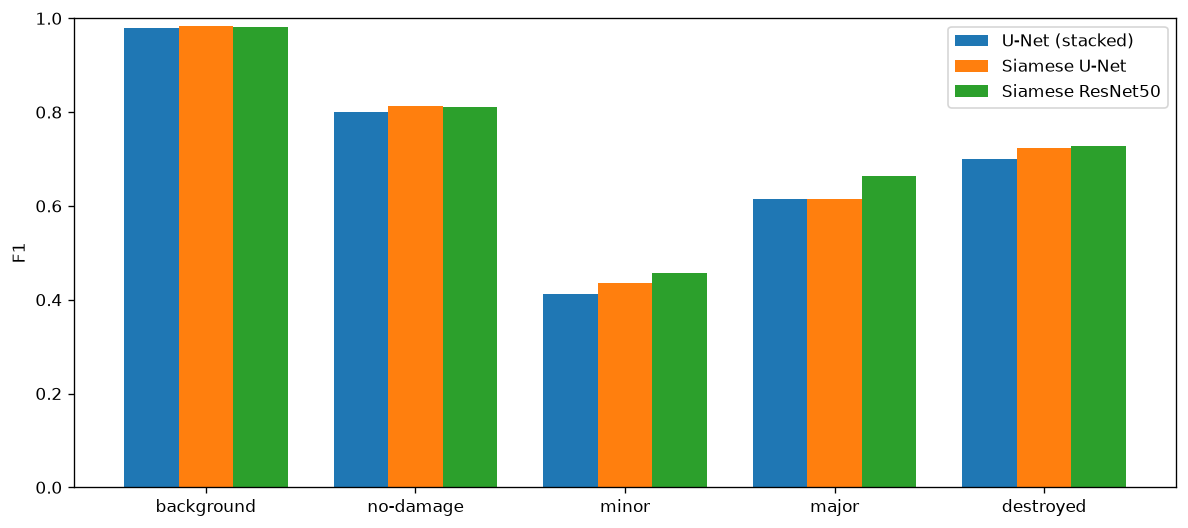

In [17]:
x = np.arange(5)
width = 0.26

pl.figure(figsize=(10, 4.5))
for i, (name, results) in enumerate(all_results.items()):
    pl.bar(x + (i - 1) * width, [results[c][2] for c in range(5)], width, label=name, color=f"C{i}")

pl.xticks(x, [config.FIVE_CLASS_NAMES[c] for c in range(5)])
pl.ylabel("F1")
pl.ylim(0, 1)
pl.legend()
pl.tight_layout()
pl.show()